# Gradient Boosting results (same structure as `results_rf.ipynb`)


## Setup

Same split, features and `experiment_results` table as the RF notebook.

In [9]:
from pathlib import Path
import matplotlib.pyplot as plt
from common import get_client

## Default model


In [7]:
df = get_client().query_df(
    "SELECT Model_Name,Train_Rows, val_lift, train_lift "
    "FROM experiment_results WHERE Model_Name = 'gb_delay_y1_f25_default'"
)

df

,Model_Name,Train_Rows,val_lift,train_lift
0,gb_delay_y1_f25_default,1728215,1.712923,1.993793


## Learning curve


In [27]:
df = get_client().query_df(
    "SELECT Model_Name, Train_Rows, val_lift, train_lift "
    "FROM experiment_results WHERE Model_Name IN ('gb_delay_y1_f12.5_curve_default', 'gb_delay_y1_f25_curve_default', 'gb_delay_y1_f50_curve_default', 'gb_delay_y1_f100_curve_default')"
)

df = df.sort_values("val_lift")
df

,Model_Name,Train_Rows,val_lift,train_lift
1,gb_delay_y1_f12.5_curve_default,864107,1.703661,2.038661
2,gb_delay_y1_f25_curve_default,1728215,1.712274,1.992504
3,gb_delay_y1_f50_curve_default,3456430,1.717912,1.968889
0,gb_delay_y1_f100_curve_default,6912859,1.720752,1.952362


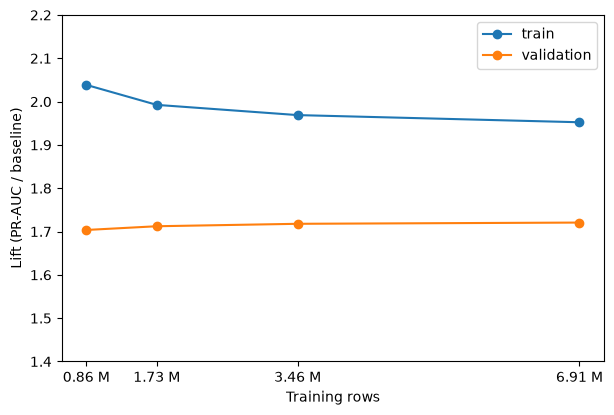

In [38]:
models = ["GB Fraction_12.5","GB Fraction_25", "GB Fraction_50", "GB Fraction_100"]

fig , ax = plt.subplots(figsize=(7, 4.5))

ax.plot(df["Train_Rows"], df["train_lift"], marker="o", label="train")
ax.plot(df["Train_Rows"], df["val_lift"], marker="o", label="validation")
ax.set_ylim(1.4,2.2)

ax.set_xticks(df["Train_Rows"])
ax.set_xticklabels([f"{r / 1e6:.2f} M" for r in df["Train_Rows"]])
ax.set_xlabel("Training rows")
ax.set_ylabel("Lift (PR-AUC / baseline)")


ax.legend()




In [35]:
fig.savefig("../docs/figures/learning_curve_gb_default.png", dpi=150, bbox_inches="tight")

## Hyperparameter tuning


### Max_iter 
##### According to the results of staged_gb_delay.ipynb, we stick with the 100 

### Max_leaf_node


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OrdinalEncoder
from sklearn.metrics import average_precision_score
from common import (
    TARGET_LABEL, FEATURES, CATEGORICAL, VAL_START, VAL_END, TRAIN_END,
    train_start_for, select_period, load_data, fit_model,
)

CAT_MASK = [True] * len(CATEGORICAL) + [False] * (len(FEATURES) - len(CATEGORICAL))

PARAMS = {"random_state": 42, "learning_rate": 0.1, "max_iter": 400, "max_leaf_nodes": 31,
          "min_samples_leaf": 20, "early_stopping": False, "categorical_features": CAT_MASK}
YEARS = 1
FRACTION = 0.25
LEAVES = [8, 15, 31, 63, 127]

df = load_data(YEARS)
train = select_period(df, train_start_for(YEARS), TRAIN_END)
validation = select_period(df, VAL_START, VAL_END)
subset = train.sample(frac=FRACTION, random_state=PARAMS["random_state"]).sort_index()
y_val = validation[TARGET_LABEL]

preprocess = ColumnTransformer(
    [("cat", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=np.nan,
                            max_categories=254), CATEGORICAL)],
    remainder="passthrough")

curves = {}


for leaves in LEAVES:
    PARAMS["max_leaf_nodes"] = leaves
    model = HistGradientBoostingClassifier(**PARAMS)
    pipeline, train_seconds = fit_model(model, subset, preprocess)


    model = pipeline.named_steps["model"]
    encoder = pipeline.named_steps["preprocess"]
    X_val = encoder.transform(validation[FEATURES])

    val_lifts = []
    for i, p_val in enumerate(model.staged_predict_proba(X_val), start=1):
        if i % 10 == 0:
            val_lifts.append(average_precision_score(y_val, p_val[:, 1]) / y_val.mean())

    curves[leaves] = val_lifts
    best = int(np.argmax(val_lifts))
    print(f"leaves {leaves}: best at {(best + 1) * 10} tree, lift {val_lifts[best]:.3f}, {train_seconds:.0f} s")



KeyboardInterrupt: 

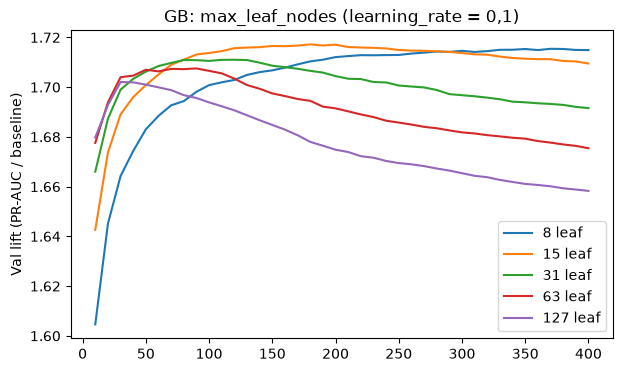

In [42]:
trees = list(range(10, PARAMS["max_iter"] + 1, 10))

fig, ax = plt.subplots(figsize=(7, 4))
for leaves in LEAVES:
    ax.plot(trees, curves[leaves], label=f"{leaves} leaf")
ax.set_ylabel("Val lift (PR-AUC / baseline)")
ax.set_title("GB: max_leaf_nodes (learning_rate = 0,1)")
ax.legend()
fig.savefig("../docs/figures/gb_tuning_max_leaf_nodes.png", dpi=150, bbox_inches="tight")

#### We choose the 15 leaf, 180 trees

### min_samples_leaf 

## Default vs final comparison
